In [1]:
#===================================  IMP LIBRARIES =====================================#

import os
#os.environ['DRJIT_LIBLLVM_PATH'] = "/home/aizi0357/environments/sionna_v0/lib/libLLVM-20.so"
#os.environ["LD_LIBRARY_PATH"] = "$LD_LIBRARY_PATH:/home/aizi0357/environments/sionna_v0/lib/"

gpu_num = "" # Use "" to use the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import sionna

resolution = [480,320] # increase for higher quality of renderings

# Allows to exit cell execution in Jupyter
class ExitCell(Exception):
    def _render_traceback_(self):
        pass

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print("gpus:", gpus)
print(f"Using GPU {gpu_num}")
if gpu_num and gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)

tf.get_logger().setLevel('ERROR')

tf.random.set_seed(1) # Set global random seed for reproducibility

tf.config.run_functions_eagerly(True)

#%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import time

# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera


gpus: []
Using GPU 


In [2]:
#===================================  SETTING THE SCENE =====================================#

dtype = tf.complex128
rdtype = tf.float64


fc = 2e9  # Se cambio la frequenza il cylinder radio diventa 12.8 / 2 per lamda giusto ??????
lamda = 3e8 / fc

print("\n==== SIMULATION PARAMETERS ===")
print(f"fc: {fc}")
print(f"lamda: {lamda}")

cylinder_radius_lamda = 20
nu = 12

cylinder_radius = cylinder_radius_lamda * lamda
print(f"cylinder_radius: {cylinder_radius}")

scene = load_scene("./models/plane/plane.xml", dtype)
#scene = load_scene("./models/cylinder_25.6_lamda/short/cylinder_12/cylinder_12.xml", dtype)

scene.frequency = fc
scene.synthetic_array = True


#================================ SETTING RX and TX =========================================#

pol = 'HH'   

scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization=pol[0],
                             dtype=dtype)

scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization=pol[1],
                             dtype=dtype)


# =============================== PLACING TX ================================================== #

# Calcola a desnità di onda incidente e il modulo del campo incidente.
# Metti il TX che rispetti fronhoufer ma la potenza va normalizzta con la potenza incidente. 
# Questo per vedere come varia il campo scatterato al varire della distanza di osservazione.
# Cambia la potenza del trasmettitore in modo che il campo indidente sia sempre 1 V/m.

# Per la simulzione CST allunga il cilindro 

# Valuta il campo a distanza maggiori di 20 lamda per vedere se alte dicretizzazioni sono quele ottime 

D = cylinder_radius
tx_dist = 2*((D*2)**2)/lamda + D # TX must be in Frahofer zone
#tx_dist = 1e6

#tx_dist = 1e3
tx_dist = 500

source_point = np.array([tx_dist, 0.0, 0.0])

tx = Transmitter(name="tx", position=source_point, dtype=dtype)

scene.remove("tx")
scene.add(tx)

coef = (4 * np.pi * tx_dist)




#================================ IMP DOUBLE EDGE DIFRACTION =========================================#

from sionna.rt.objects_geometry import ObjectsGeometry

obj_names = list(scene.objects.keys())

obj_geom = ObjectsGeometry(scene._solver_paths)
obj_geom.is_table_gfi = True
obj_geom.is_vertex_diffraction = True
obj_geom.is_double_diffraction = True
obj_geom.init_objects(obj_names, [None])

scene._solver_paths.vertex_diffraction.set_objects_geometry(obj_geom)
scene._solver_paths.double_diffraction.set_objects_geometry(obj_geom)

# tf.math.reduce_mean(scene._solver_paths._wedges_length) / lamda


==== SIMULATION PARAMETERS ===
fc: 2000000000.0
lamda: 0.15
cylinder_radius: 3.0


2026-08-31 10:54:18 WARN wrk1 [PLYMesh] "plane.ply": attributes without postfix are not handled for now: attribute "stl" ignored.

num_edges: tf.Tensor(4, shape=(), dtype=int32)
num_wedges: 560
num vertices: 288


In [3]:
# ============================== PLACING RX ==================================================== #
circle_radius = cylinder_radius + lamda*np.array([5, 10, 15])
lables = ['5', '10', '15']
results = []
analytical = []

for circle_radius_i in circle_radius:

    num_points = 100
    
    #theta_arr = np.linspace(3/4*np.pi, 5/4*np.pi, num_points, endpoint=False)
    theta_arr = np.linspace(0, 2*np.pi, num_points, endpoint=False)
    
    
    def get_circle_points(theta_arr, p1, p2):
        res = np.zeros((len(theta_arr), 3))
        res[:, 0] = p1[0] * np.cos(theta_arr) + p2[0] * np.sin(theta_arr)
        res[:, 1] = p1[1] * np.cos(theta_arr) + p2[1] * np.sin(theta_arr)
        res[:, 2] = p1[2] * np.cos(theta_arr) + p2[2] * np.sin(theta_arr)
    
        return res
    
    circle_p1 = np.array([1, 0, 0]) * circle_radius_i
    circle_p2 = np.array([0, 1, 0])  * circle_radius_i
    receive_points = get_circle_points(theta_arr, circle_p1, circle_p2)
    
    
    for i in range(len(receive_points)):
        scene.remove(f"rx_{i}")
        rx = Receiver(name=f"rx_{i}", position=receive_points[i], dtype=dtype)
        scene.add(rx)
        
 #== Calculating the TOTAL FIELD WITH DOUBLE-EDGE DIFFRACTION
    
    paths = scene.compute_paths(max_depth=1,
                                method="exhaustive",
                                num_samples=1e6,
                                los = True,
                                reflection = False,
                                diffraction = True,
                                vertex_diffraction = True,
                                double_diffraction = True)
        
    a, tau = paths.cir()
    #a.shape   # [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, max_num_paths, num_time_steps]
        
    nans_bool = tf.math.is_nan(tf.math.real(a)) 
    a = tf.where(nans_bool, tf.zeros_like(a), a)
        
    path_amplitudes = a[0,:,0,0,0,:,0]
    tmp1 = np.sum(path_amplitudes, axis=1)
    receiver_amplitudes = np.abs(tmp1) / lamda
    
    
    coef = (4 * np.pi * tx_dist)

    results.append(20*np.log10(coef*receiver_amplitudes))

print(results)

/home/matte/Documenti/Materiale per tesi/sionna-RT-reflectivity-main/sionna/rt/double_diffraction.py:2963: RuntimeWarning: divide by zero encountered in divide
  spreading_factor = np.sqrt(r1) / (np.sqrt(l * r2) * np.sqrt(r1 + l + r2))
/tmp/ipykernel_3342/2682617504.py:57: RuntimeWarning: divide by zero encountered in log10
  results.append(20*np.log10(coef*receiver_amplitudes))


[array([ 4.93488892e-01,  2.17194392e-01, -2.13123939e+00, -3.36136066e+00,
       -7.61942578e-01,  1.46267691e+00, -4.52071354e-01,  5.39184003e-02,
       -5.00952322e-01,  3.25402550e-02, -4.12726472e-02,  7.08697693e-01,
       -2.24376539e-01,  2.52414423e+00,  1.55318314e-01,  4.59837555e-01,
       -4.56988866e-02,  1.40063671e+00, -2.56982950e-01, -1.61477089e+00,
        4.68996300e-01,  1.85994516e+00, -2.79788643e+00,  8.86485470e-01,
                  -inf,            -inf,            -inf, -4.02355176e+01,
       -3.17173801e+01, -2.90525764e+01, -3.36508126e+01, -3.17354952e+01,
       -3.08100713e+01, -2.92673207e+01, -4.11050433e+01, -3.58996045e+01,
       -3.94224514e+01, -4.02999508e+01, -4.12229790e+01, -4.09521588e+01,
       -4.03039069e+01, -3.75992593e+01, -3.43823028e+01, -3.70662725e+01,
       -4.17192854e+01, -4.55832142e+01, -4.50730902e+01, -4.14271140e+01,
       -3.79171704e+01, -3.55681857e+01, -3.47965288e+01, -3.54938228e+01,
       -3.73176254e+01, 

<Figure size 640x480 with 0 Axes>

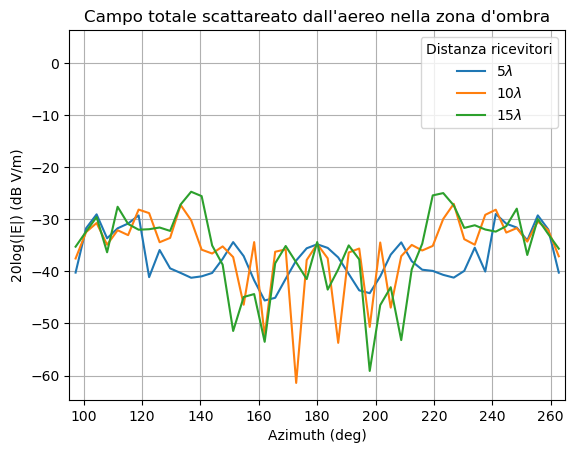

In [12]:
plt.figure()
fig, ax = plt.subplots()
plt.title(rf"Campo totale scattareato dall'aereo nella zona d'ombra")
j = 0
for i in results:
    plt.plot(57.3*theta_arr, i, label=lables[j]+r"$\lambda$")
    j += 1
plt.legend(title="Distanza ricevitori")
plt.xlabel("Azimuth (deg)")
plt.ylabel("20log(|E|) (dB V/m)")
plt.xlim([95, 265])
plt.grid()
plt.savefig(f".//plane_total_field.png")